# 03 — Baseline Response Model and Why It Fails as an Uplift Ranker

**Question.** A standard response model predicts $P(Y = 1 \mid X)$. Used as a *targeting* tool, does it concentrate the campaign budget on the customers the campaign actually moves?

We will fit a logistic response model, evaluate its discrimination with ROC-AUC, then re-evaluate it as an uplift ranker via a Qini curve. The two views diverge sharply: the same model that ranks converters well ranks *persuadables* badly.

In [1]:
import sys
from pathlib import Path

_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_marketing.notebook_utils import setup_notebook, save_figure
from uplift_marketing.data import load_default_uplift_data

config = setup_notebook()
RANDOM_STATE = 42

dataset = load_default_uplift_data(config.raw_dir, random_state=RANDOM_STATE)
data = dataset.data
print(f"data source: {dataset.source} ({len(data):,} rows)")
print(f"observed treated share: {data['treatment'].mean():.3f} "
      f"(expected {dataset.expected_treated_share:.3f})")
print(f"feature columns to exclude: {dataset.extra_excluded}")


data source: hillstrom (64,000 rows)
observed treated share: 0.667 (expected 0.667)
feature columns to exclude: ['customer_id']


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

from uplift_marketing.features import (
    infer_feature_spec,
    build_preprocessor,
    split_features_treatment_outcome,
)
from uplift_marketing.evaluation import qini_curve, area_under_qini

spec = infer_feature_spec(data, extra_excluded=dataset.extra_excluded)
x, treatment, y = split_features_treatment_outcome(data, spec)

x_tr, x_te, t_tr, t_te, y_tr, y_te = train_test_split(
    x, treatment, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=treatment.astype(str) + "_" + y.astype(str),
)
print(f"train rows: {len(x_tr):,}; test rows: {len(x_te):,}")

train rows: 44,800; test rows: 19,200


## 1. Fit the response model

The model ignores the treatment column on purpose: a response model is a *marginal* predictor of conversion, not a conditional-on-treatment predictor.

In [3]:
response_model = Pipeline(
    [
        ("preprocessor", build_preprocessor(spec)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]
).fit(x_tr, y_tr)

response_score_te = response_model.predict_proba(x_te)[:, 1]
auc = roc_auc_score(y_te, response_score_te)
print(f"test ROC-AUC for predicting conversion: {auc:.3f}")

test ROC-AUC for predicting conversion: 0.577


## 2. Re-evaluating the same scores as an uplift ranker

If we use the response score to *rank* customers, we are implicitly betting that high-conversion-probability customers are also high-uplift customers. The Qini curve checks that bet directly: customers are sorted by score, and at each prefix we read off the incremental conversions estimated as $T_+ - C_+ \cdot N_T / N_C$, where $T_+$, $C_+$ are cumulative treated and control conversions and $N_T$, $N_C$ are cumulative arm sizes.

In [4]:
qini_response = qini_curve(
    outcome=y_te.to_numpy(),
    treatment=t_te.to_numpy(),
    uplift_score=response_score_te,
)
auq_response = area_under_qini(qini_response)

rng = np.random.default_rng(RANDOM_STATE)
random_score = rng.uniform(size=len(y_te))
qini_random = qini_curve(
    outcome=y_te.to_numpy(),
    treatment=t_te.to_numpy(),
    uplift_score=random_score,
)
auq_random = area_under_qini(qini_random)
print(f"area under Qini, response-ranked: {auq_response:.4f}")
print(f"area under Qini, random ranking:  {auq_random:.4f}")
print(f"gap (response - random):          {auq_response - auq_random:+.4f}")

area under Qini, response-ranked: 30.9204
area under Qini, random ranking:  36.4493
gap (response - random):          -5.5289


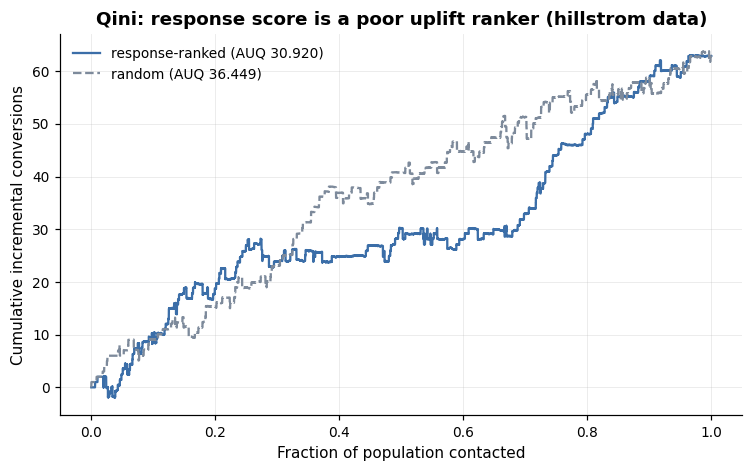

In [5]:
fig, ax = plt.subplots()
ax.plot(
    qini_response["population_fraction"],
    qini_response["incremental_gain"],
    label=f"response-ranked (AUQ {auq_response:.3f})",
    color="#3b6ea8",
)
ax.plot(
    qini_random["population_fraction"],
    qini_random["incremental_gain"],
    label=f"random (AUQ {auq_random:.3f})",
    color="#7d8a9b",
    linestyle="--",
)
ax.set_xlabel("Fraction of population contacted")
ax.set_ylabel("Cumulative incremental conversions")
ax.set_title(
    f"Qini: response score is a poor uplift ranker ({dataset.source} data)"
)
ax.legend()
save_figure(fig, "03_qini_response_vs_random")
plt.show()

## 3. Decile lift when ranking by response score

If response-ranking were a good uplift policy, the leftmost (highest-score) deciles would carry most of the observed treated-control gap.

In [6]:
test = pd.DataFrame(
    {
        "response_score": response_score_te,
        "treatment": t_te.to_numpy(),
        "conversion": y_te.to_numpy(),
    }
)
test["response_decile"] = (
    pd.qcut(test["response_score"].rank(method="first", ascending=False), 10, labels=False) + 1
)
decile_lift = (
    test.groupby("response_decile")
    .apply(
        lambda g: pd.Series(
            {
                "n": len(g),
                "treated_rate": g.loc[g.treatment == 1, "conversion"].mean(),
                "control_rate": g.loc[g.treatment == 0, "conversion"].mean(),
                "observed_uplift": (
                    g.loc[g.treatment == 1, "conversion"].mean()
                    - g.loc[g.treatment == 0, "conversion"].mean()
                ),
            }
        ),
        include_groups=False,
    )
    .reset_index()
)
decile_lift

,response_decile,n,treated_rate,control_rate,observed_uplift
0,1,1920.0,0.018110,0.010769,0.007341
1,2,1920.0,0.015373,0.008078,0.007295
2,3,1920.0,0.011774,0.007740,0.004034
3,4,1920.0,0.007004,0.006299,0.000705
4,5,1920.0,0.007137,0.003035,0.004102
5,6,1920.0,0.009353,0.010989,-0.001636
6,7,1920.0,0.008527,0.004762,0.003765
7,8,1920.0,0.013365,0.001543,0.011822
8,9,1920.0,0.009368,0.001565,0.007803
9,10,1920.0,0.006971,0.003180,0.003792


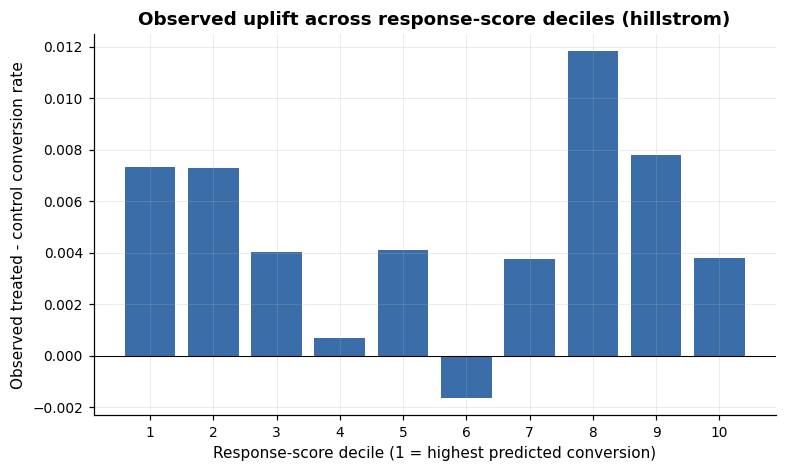

In [7]:
fig, ax = plt.subplots()
ax.bar(decile_lift["response_decile"], decile_lift["observed_uplift"], color="#3b6ea8")
ax.axhline(0, color="black", linewidth=0.7)
ax.set_xticks(decile_lift["response_decile"])
ax.set_xlabel("Response-score decile (1 = highest predicted conversion)")
ax.set_ylabel("Observed treated - control conversion rate")
ax.set_title(f"Observed uplift across response-score deciles ({dataset.source})")
save_figure(fig, "03_response_decile_lift")
plt.show()

## 4. Takeaway

- The response model has a respectable conversion ROC-AUC.
- The same model, used as an uplift ranker, sits close to the random baseline on the Qini curve. The AUQ gap of response over random is small relative to the gap an uplift model achieves in notebook 04.
- Decile lift is roughly flat across response deciles: the highest-conversion segment is dominated by sure things, not persuadables.

The fix is to estimate the **conditional treatment effect** directly. That is the job of the meta-learners in notebook 04.